# Does this groundwater CSV cover Jharkhand and Odisha?

Run all cells using this project's `.venv` Python kernel. The CSV stays local: the ArcGIS Python API only queries public Esri state boundaries, without a login or uploading station data. Internet is required for that query.

The map shows **evidence locations, not water safety**. Repeated chemistry records are grouped into station-location markers; they are not counted as separate wells. Change `CSV_PATH` below to inspect the next export.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.path import Path as PolygonPath
from arcgis.features import FeatureLayer
from IPython.display import display

ROOT = Path.cwd()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
CSV_PATH = ROOT / 'input_reports' / 'ground_water_quality_manual_half_yearly_1972_2025.csv'
df = pd.read_csv(CSV_PATH, encoding='utf-8-sig', dtype='string', keep_default_na=False)
required = {'Station Code', 'Station Name', 'Agency Name', 'State', 'District',
            'Latitude', 'Longitude', 'Sample Collection Date'}
missing = required - set(df.columns)
if missing:
    raise ValueError(f'Missing required CSV columns: {sorted(missing)}')
df['state_normalized'] = df['State'].str.strip().str.casefold().replace({'orissa': 'odisha'})
df['latitude'] = pd.to_numeric(df['Latitude'], errors='coerce')
df['longitude'] = pd.to_numeric(df['Longitude'], errors='coerce')
dates = df['Sample Collection Date'].str.strip()
df['sample_date'] = pd.to_datetime(dates, format='%d-%m-%Y', errors='coerce')
alternate = df['sample_date'].isna()
df.loc[alternate, 'sample_date'] = pd.to_datetime(dates[alternate], format='%d-%b-%y', errors='coerce')
valid_coordinates = df['latitude'].between(-90, 90) & df['longitude'].between(-180, 180)
station_key = ['Agency Name', 'Station Code']
location_key = station_key + ['state_normalized', 'latitude', 'longitude']
stations = (df.loc[valid_coordinates].groupby(location_key, dropna=False)
            .agg(records=('Station Name', 'size'), first_date=('sample_date', 'min'),
                 last_date=('sample_date', 'max')).reset_index())
print(f'{len(df):,} records; {len(df[station_key].drop_duplicates()):,} agency/station IDs; '
      f'{len(stations):,} valid station-location markers')
print(f'Parsed sample dates: {df.sample_date.min()} to {df.sample_date.max()}')
print(f'Unparsed dates: {df.sample_date.isna().sum():,}; invalid coordinates: {(~valid_coordinates).sum():,}')
print(f'Missing station codes: {df["Station Code"].str.strip().isin(["", "-"]).sum():,}')
display(df.groupby(['State', 'Agency Name'], dropna=False).size().rename('records').to_frame())

113,586 records; 3,828 agency/station IDs; 3,828 valid station-location markers
Parsed sample dates: 1972-01-01 00:00:00 to 2025-07-09 00:00:00
Unparsed dates: 0; invalid coordinates: 0
Missing station codes: 0


,,records
State,Agency Name,
Tamil Nadu,Tamil Nadu SW GW,113586


In [2]:
TARGETS = {'JH': 'Jharkhand', 'OR': 'Odisha'}
summary = []
for name in TARGETS.values():
    subset = df[df.state_normalized == name.casefold()]
    summary.append({'target_state': name, 'labelled_records': len(subset),
                    'agency_station_ids': len(subset[station_key].drop_duplicates()),
                    'districts_in_file': subset.District.nunique()})
display(pd.DataFrame(summary).set_index('target_state'))
parameter_columns = list(df.columns[df.columns.get_loc('Sample Collection Date') + 1:
                                   df.columns.get_loc('state_normalized')])
present = ~df[parameter_columns].apply(lambda column: column.str.strip().str.casefold().isin(['', '-', 'na', 'n/a', 'null']))
display(pd.DataFrame({'records_with_value': present.sum(),
                      'missing_percent': ((~present).mean() * 100).round(1)}))
if not df.state_normalized.isin([name.casefold() for name in TARGETS.values()]).any():
    print('No records are labelled Jharkhand or Odisha. Check the export state/agency filters.')

,labelled_records,agency_station_ids,districts_in_file
target_state,,,
Jharkhand,0,0,0
Odisha,0,0,0


,records_with_value,missing_percent
Electric Conductivity (EC_GEN),113577,0.0
Potential of Hydrogen_Gen (pH_GEN),107268,5.6
Total Dissolved Solids (TDS),110632,2.6
Nitrate (NO3),113584,0.0
Nitrate N (NO3-N),93608,17.6
Total Hardness (HAR_Total),110418,2.8
Carbonate (CO3),110394,2.8
Calcium (Ca),110411,2.8
Chloride (Cl),113551,0.0
Bicarbonate (HCO3),110407,2.8


No records are labelled Jharkhand or Odisha. Check the export state/agency filters.


## Retrieve outlines through the ArcGIS Python API

[World Administrative Divisions](https://services.arcgis.com/P3ePLMYs2RVChkJx/ArcGIS/rest/services/World_Administrative_Divisions/FeatureServer/0) is a public Esri feature layer. Query **ISO subdivision codes**, not names: this service uses accented names for Jharkhand and Tamil Nadu. Tamil Nadu is included for orientation because that is the downloaded file's stated coverage.

Boundary coordinates are requested in WGS84 and rounded to four decimal places for this screening visual. They are not survey-grade or an authoritative current district crosswalk. Points near borders need a precise spatial check. Service access failures stop the notebook explicitly; no substitute outlines are silently drawn.

In [3]:
BOUNDARY_URL = ('https://services.arcgis.com/P3ePLMYs2RVChkJx/ArcGIS/rest/services/'
                'World_Administrative_Divisions/FeatureServer/0')
layer = FeatureLayer(BOUNDARY_URL)
boundary_features = layer.query(
    where="ISO_CC = 'IN' AND ISO_SUB IN ('JH', 'OR', 'TN')",
    out_fields='NAME,ISO_CC,ISO_SUB', out_sr=4326,
    geometry_precision=4,
)
if {feature.attributes['ISO_SUB'] for feature in boundary_features.features} != {'JH', 'OR', 'TN'}:
    raise ValueError('Boundary query did not return all three expected states.')
boundaries = {code: [] for code in ['JH', 'OR', 'TN']}
for feature in boundary_features.features:
    if not feature.geometry or not feature.geometry.get('rings'):
        raise ValueError(f'Boundary is missing polygon rings: {feature.attributes}')
    boundaries[feature.attributes['ISO_SUB']].append(feature.geometry['rings'])
print(layer.properties.copyrightText)
display(pd.DataFrame([feature.attributes for feature in boundary_features.features]))

Sources: Esri; Garmin International, Inc.


,FID,NAME,ISO_CC,ISO_SUB
0,1832,Jhārkhand,IN,JH
1,1850,Odisha,IN,OR
2,1851,Odisha,IN,OR
3,1852,Odisha,IN,OR
4,1858,Tamil Nādu,IN,TN
5,1859,Tamil Nādu,IN,TN
6,1860,Tamil Nādu,IN,TN


In [4]:
def within_outline(points, polygons):
    inside = np.zeros(len(points), dtype=bool)
    for rings in polygons:
        in_polygon = np.zeros(len(points), dtype=bool)
        for ring in rings:
            # Even-odd membership retains polygon holes and separate islands.
            in_polygon ^= PolygonPath(np.asarray(ring)).contains_points(points)
        inside |= in_polygon
    return inside

points = stations[['longitude', 'latitude']].to_numpy(dtype=float)
spatial_summary = []
for code, name in TARGETS.items():
    mask = within_outline(points, boundaries[code])
    stations[f'inside_{code}'] = mask
    spatial_summary.append({'target_state': name, 'markers_inside_outline': int(mask.sum()),
                            'records_at_those_markers': int(stations.loc[mask, 'records'].sum())})
display(pd.DataFrame(spatial_summary).set_index('target_state'))
print('Spatial counts use approximate outlines, independently of the CSV state labels.')

,markers_inside_outline,records_at_those_markers
target_state,,
Jharkhand,0,0
Odisha,0,0


Spatial counts use approximate outlines, independently of the CSV state labels.


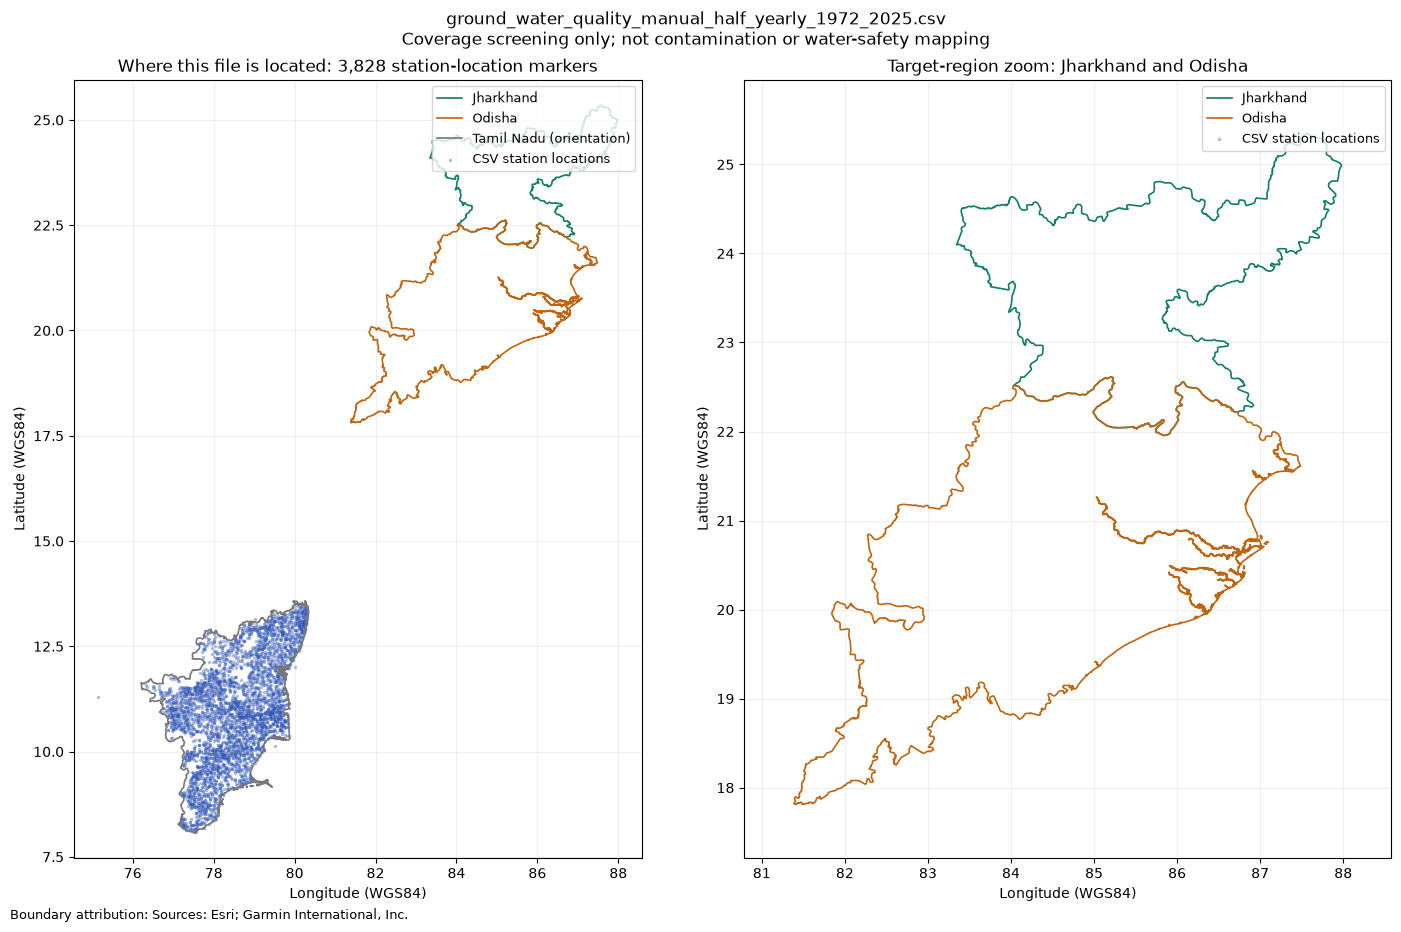

Conclusion: this export provides no location coverage for either target region. Obtain another state-filtered export.


In [5]:
colors = {'JH': '#137c66', 'OR': '#be6512', 'TN': '#777777'}
names = {**TARGETS, 'TN': 'Tamil Nadu (orientation)'}
fig, axes = plt.subplots(1, 2, figsize=(14, 9), layout='constrained')

for ax, codes in zip(axes, [('JH', 'OR', 'TN'), ('JH', 'OR')]):
    for code in codes:
        labelled = False
        for rings in boundaries[code]:
            for ring in rings:
                xy = np.asarray(ring)
                ax.plot(xy[:, 0], xy[:, 1], color=colors[code], linewidth=1.2,
                        label=names[code] if not labelled else None)
                labelled = True
    ax.scatter(stations.longitude, stations.latitude, s=6, alpha=0.4,
               color='#3157b7', linewidths=0, label='CSV station locations')
    ax.set(xlabel='Longitude (WGS84)', ylabel='Latitude (WGS84)')
    ax.grid(alpha=0.2)
    ax.legend(loc='upper right', fontsize=9)

all_boundary_points = np.concatenate([np.asarray(ring) for polygons in boundaries.values()
                                      for rings in polygons for ring in rings])
overview_points = np.vstack([all_boundary_points, points])
target_points = np.concatenate([np.asarray(ring) for code in TARGETS
                                for rings in boundaries[code] for ring in rings])
for ax, extent in zip(axes, [overview_points, target_points]):
    lower, upper = extent.min(axis=0), extent.max(axis=0)
    ax.set_xlim(lower[0] - 0.6, upper[0] + 0.6)
    ax.set_ylim(lower[1] - 0.6, upper[1] + 0.6)
    ax.set_aspect(1 / np.cos(np.deg2rad(extent[:, 1].mean())))
axes[0].set_title(f'Where this file is located: {len(stations):,} station-location markers')
axes[1].set_title('Target-region zoom: Jharkhand and Odisha')
fig.suptitle(f'{CSV_PATH.name}\nCoverage screening only; not contamination or water-safety mapping', fontsize=12)
fig.text(0.01, -0.015, f'Boundary attribution: {layer.properties.copyrightText}', fontsize=9)
plt.show()

inside_any_target = stations['inside_JH'] | stations['inside_OR']
if not inside_any_target.any() and not df.state_normalized.isin(['jharkhand', 'odisha']).any():
    print('Conclusion: this export provides no location coverage for either target region. Obtain another state-filtered export.')
else:
    print('Some target coverage exists. Compare the labelled and spatial counts above, then inspect dates and parameters.')

## Interpretation and next download

- For this file, the agency field is **Tamil Nadu SW GW**, not CGWB. The generic filename does not identify its geographic or agency coverage.
- Dates use both `DD-MM-YYYY` and `DD-Mon-YY`; the notebook parses both and explicitly counts remaining failures. Publication/export dates and sampling dates are different.
- The presence table counts nonblank entries, **not validated measurements**. Units, detection-limit qualifiers and analytical methods need the portal metadata before concentration comparisons.
- This CSV has no well construction, screened intervals or aquifer depth fields, and no iron/arsenic columns. Do not infer those properties or water safety from these markers.
- Original records are not deduplicated or altered. Markers group agency/station ID, labelled state and coordinates; changed coordinates remain separate locations. Coincident markers may overlap visually.
- Download Jharkhand and Odisha exports separately, preserving the portal URL, dataset title, agency, state/year filters, metadata and reuse terms. Re-run this notebook with each new filename.
- This is a local inspection notebook, not a public release. Check dataset and boundary-service reuse terms before redistributing files or figures.